In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [32]:
df = pd.read_csv('auto-mpg.csv')
# 1. Pehle '?' ko NaN mein convert karke numeric (float) banayein
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

# 2. Agar NaN values ko median ya kisi aur value se fill karna ho (optional)
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())

# 3. Ab ise cleanly integer mein convert kar sakte hain
df['horsepower'] = df['horsepower'].astype(int)

In [37]:
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model year,origin,car name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86,2790,15.6,82,1,ford mustang gl
394,44.0,4,97.0,52,2130,24.6,82,2,vw pickup
395,32.0,4,135.0,84,2295,11.6,82,1,dodge rampage
396,28.0,4,120.0,79,2625,18.6,82,1,ford ranger


<Axes: xlabel='mpg', ylabel='Density'>

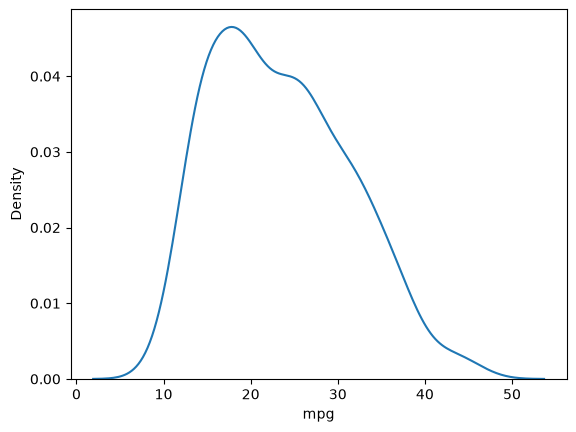

In [34]:
x = df.select_dtypes('number')
sns.kdeplot(df['mpg'])

<Axes: >

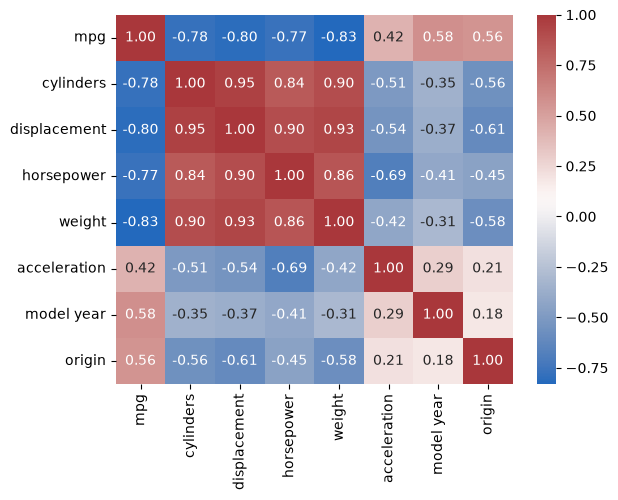

In [35]:
sns.heatmap(x.corr(),annot=True,fmt='.2f',cmap='vlag')

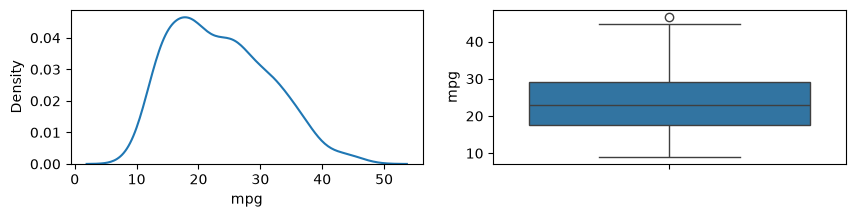

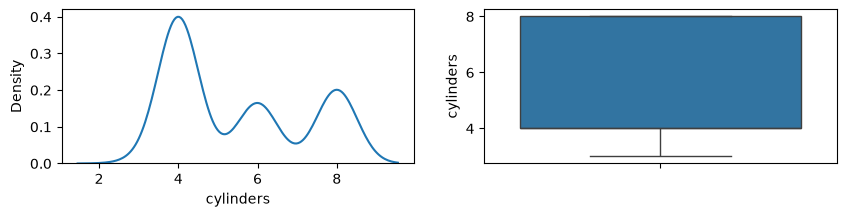

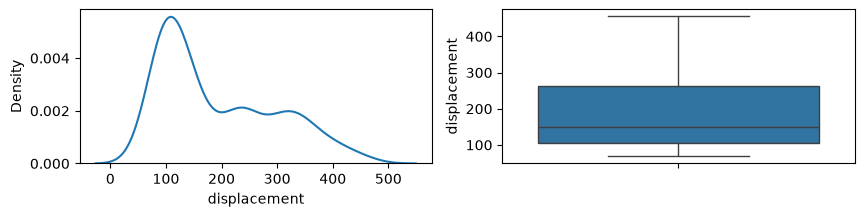

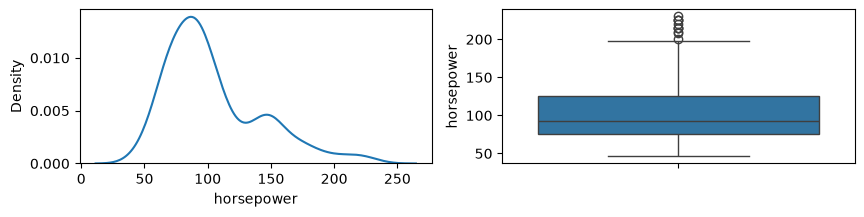

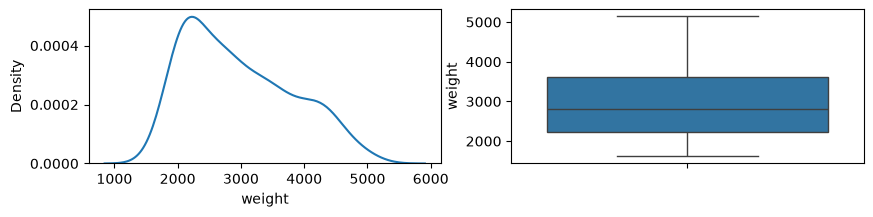

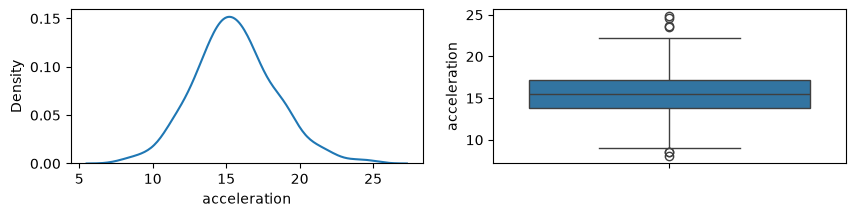

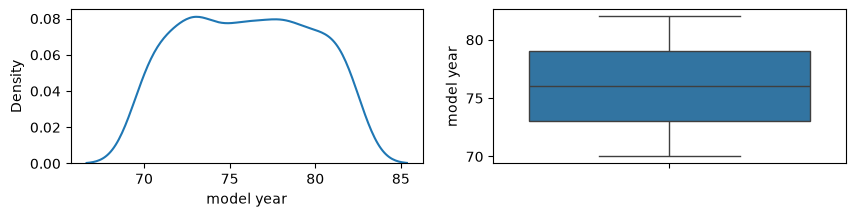

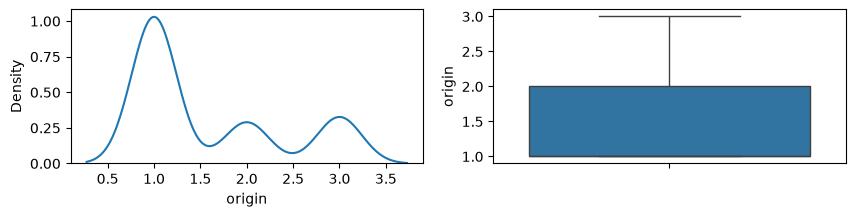

In [36]:
for i in x.columns:
    plt.figure(figsize=(10,2))
    plt.subplot(1,2,1)
    sns.kdeplot(df[i])
    plt.subplot(1,2,2)
    sns.boxplot(df[i])

In [43]:
from sklearn.preprocessing import PowerTransformer
pi = PowerTransformer(method='yeo-johnson')
df['mpg'] = pi.fit_transform(df[['mpg']])
df['displacement'] = pi.fit_transform(df[['displacement']])
df['horsepower'] = pi.fit_transform(df[['horsepower']])
df['weight'] = pi.fit_transform(df[['weight']])
df['acceleration'] = pi.fit_transform(df[['acceleration']])

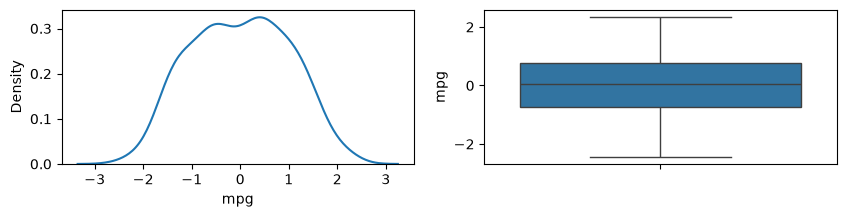

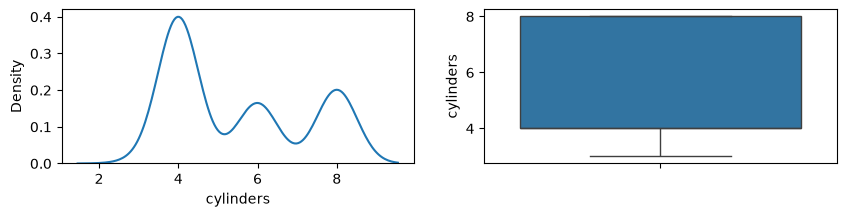

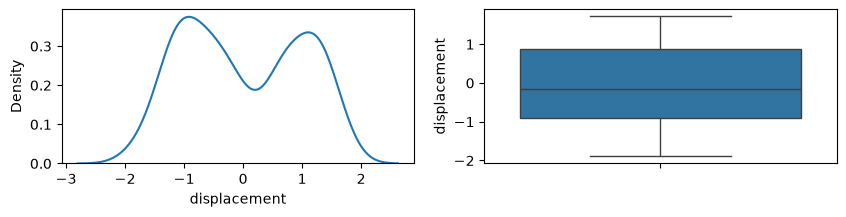

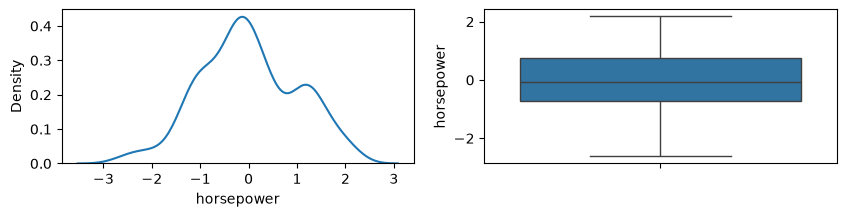

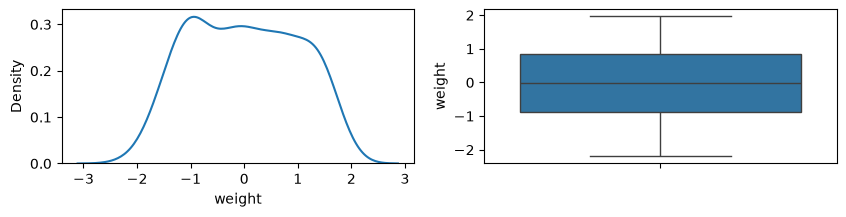

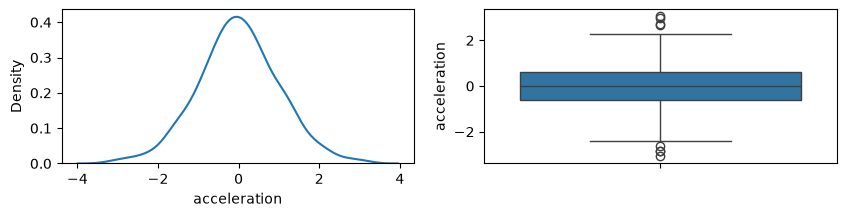

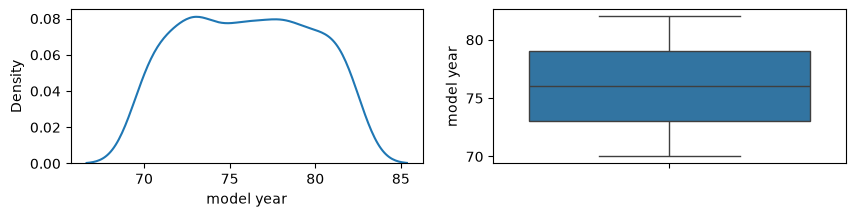

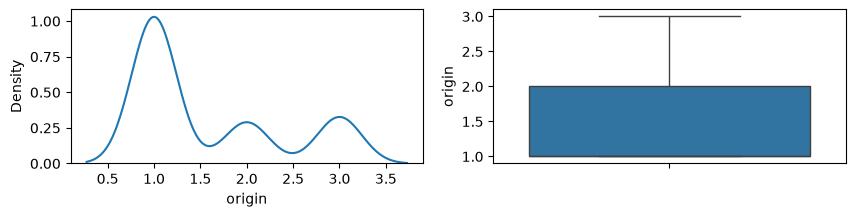

In [44]:
for i in x.columns:
    plt.figure(figsize=(10,2))
    plt.subplot(1,2,1)
    sns.kdeplot(df[i])
    plt.subplot(1,2,2)
    sns.boxplot(df[i])

In [46]:
Q1 = df['acceleration'].quantile(0.25)
Q3 = df['acceleration'].quantile(0.75)
IQR = Q3 - Q1
maxx =  1.5*IQR*(Q3)
minn = Q1 - 1.5 * IQR

In [47]:
def solve(x):
    if(x>maxx):
        return maxx
    elif(x<minn):
        return minn;
    else:
        return x
    

In [48]:
df['acceleration'] = df['acceleration'].apply(solve)

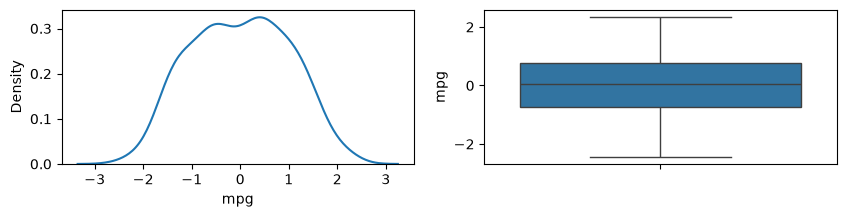

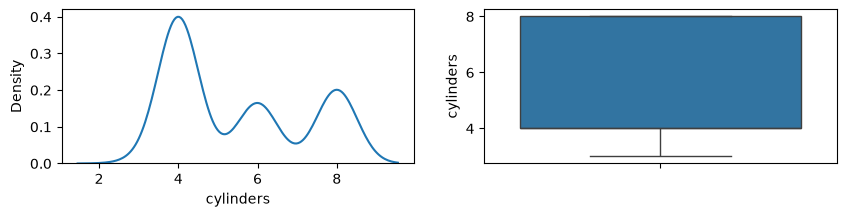

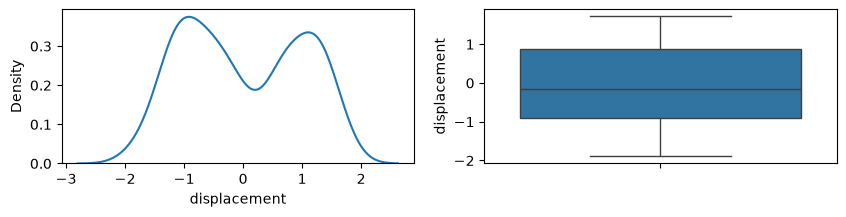

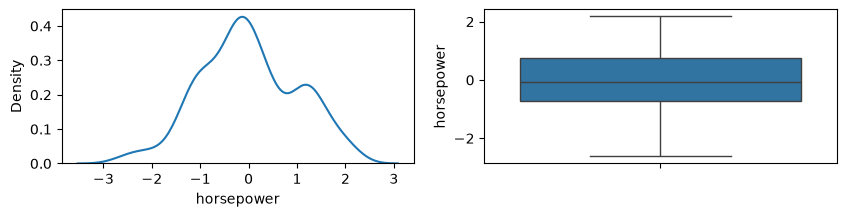

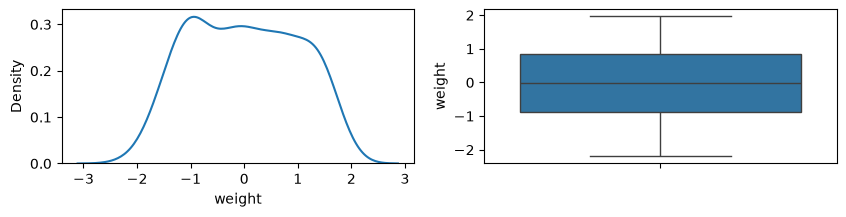

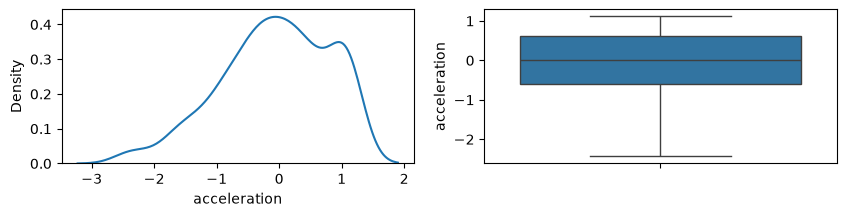

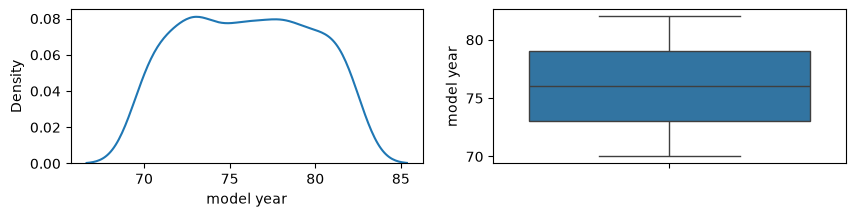

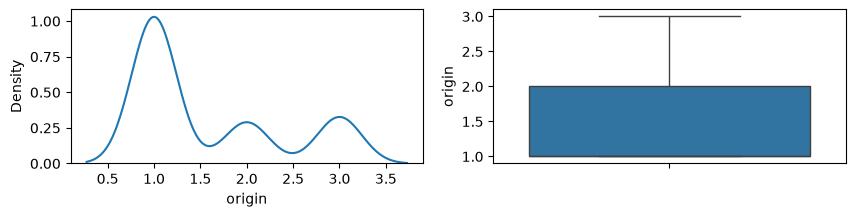

In [49]:
for i in x.columns:
    plt.figure(figsize=(10,2))
    plt.subplot(1,2,1)
    sns.kdeplot(df[i])
    plt.subplot(1,2,2)
    sns.boxplot(df[i])

In [54]:
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test = train_test_split(df.drop(columns=['mpg','car name']),df['mpg'],test_size=0.2,random_state=2)

In [55]:
from sklearn.linear_model import LinearRegression
li = LinearRegression()
li.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[-0.06,-0.04,-0.33,...,-0.16, 0.09, 0.05]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['cylinders','displacement','horsepower',...,'acceleration','model year', 'origin']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-6.497
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [62]:
u =li.predict(X_train)
y_pred = li.predict(X_test)

In [64]:
from sklearn.metrics import r2_score,mean_squared_error
r2_score(Y_train,u)

0.8851931824075665

In [63]:

r2_score(Y_test,y_pred)

0.8902113034127683

In [65]:
np.sqrt(mean_squared_error(Y_test,y_pred))

np.float64(0.3387197821681915)

In [66]:
from sklearn.preprocessing import PolynomialFeatures

In [67]:
poly = PolynomialFeatures(include_bias=False,degree=2)

In [68]:
x_train_trf = poly.fit_transform(X_train)
x_test_trf = poly.transform(X_test)

In [71]:
li.fit(x_train_trf,Y_train)
y_pred_2 = li.predict(x_test_trf)
r2_score(Y_test,li.predict(x_test_trf))

0.8632790174161211

In [72]:
r2_score(Y_train,li.predict(x_train_trf))

0.9175181320361407

In [74]:
np.sqrt(mean_squared_error(Y_test,y_pred_2))

np.float64(0.3779891486523569)

In [84]:
poly = PolynomialFeatures(include_bias=False,degree=3)
X_train_trf = poly.fit_transform(X_train)
X_test_trf = poly.transform(X_test)

li.fit(X_train_trf,Y_train)
r2_score(Y_test,li.predict(X_test_trf))

0.8281045476005601